In [1]:
pip install tensorflow scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [3]:
IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 40

train_dir = "D:/Maize/Dataset/split_dataset/train"
val_dir = "D:/Maize/Dataset/split_dataset/val"
test_dir = "D:/Maize/Dataset/split_dataset/test"

In [4]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

Found 9600 files belonging to 8 classes.
Found 584 files belonging to 8 classes.
Found 594 files belonging to 8 classes.


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [7]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.2),
])

In [8]:
def cbam_block(input_feature, ratio=8):

    channel = input_feature.shape[-1]

    shared_layer_one = tf.keras.layers.Dense(channel//ratio,
                                              activation='relu')
    shared_layer_two = tf.keras.layers.Dense(channel)

    avg_pool = tf.keras.layers.GlobalAveragePooling2D()(input_feature)
    avg_pool = tf.keras.layers.Reshape((1,1,channel))(avg_pool)
    avg_pool = shared_layer_one(avg_pool)
    avg_pool = shared_layer_two(avg_pool)

    max_pool = tf.keras.layers.GlobalMaxPooling2D()(input_feature)
    max_pool = tf.keras.layers.Reshape((1,1,channel))(max_pool)
    max_pool = shared_layer_one(max_pool)
    max_pool = shared_layer_two(max_pool)

    cbam_feature = tf.keras.layers.Add()([avg_pool, max_pool])
    cbam_feature = tf.keras.layers.Activation('sigmoid')(cbam_feature)

    return tf.keras.layers.Multiply()([input_feature, cbam_feature])

In [9]:
base_model = tf.keras.applications.EfficientNetB3(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

In [10]:
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.efficientnet.preprocess_input(x)

x = base_model(x, training=False)

x = cbam_block(x)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dense(256, activation='relu')(x)

x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 256, 256, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 256, 256, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ efficientnetb3 (Functional)   │ (None, 8, 8, 1536)        │      10,783,535 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 1536)              │               0 │ efficientnetb3[0][0]       │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_max_pooling2d          │ (None, 1536)              │               0 │ efficientnetb3[0][0]       │
│ (GlobalMaxPooling2D)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 1, 1, 1536)        │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 1, 1, 1536)        │               0 │ global_max_pooling2d[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 1, 1, 192)         │         295,104 │ reshape[0][0],             │
│                               │                           │                 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 1, 1, 1536)        │         296,448 │ dense[0][0], dense[1][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 1, 1, 1536)        │               0 │ dense_1[0][0],             │
│                               │                           │                 │ dense_1[1][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 1, 1, 1536)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 8, 8, 1536)        │               0 │ efficientnetb3[0][0],      │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d_1    │ (None, 1536)              │               0 │ multiply[0][0]             │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 1536)              │           6,144 │ global_average_pooling2d_… │
│ (BatchNormalization)          │                           │               

 Total params: 11,776,759 (44.92 MB)

 Trainable params: 990,152 (3.78 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

In [12]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=4
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_maize_model.keras",
        monitor='val_accuracy',
        save_best_only=True
    )
]

In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 1104s 2s/step - accuracy: 0.6305 - loss: 1.0867 - val_accuracy: 0.8784 - val_loss: 0.3524 - learning_rate: 1.0000e-04
Epoch 2/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 1404s 2s/step - accuracy: 0.7969 - loss: 0.5931 - val_accuracy: 0.9127 - val_loss: 0.2725 - learning_rate: 1.0000e-04
Epoch 3/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 1051s 2s/step - accuracy: 0.8388 - loss: 0.4582 - val_accuracy: 0.9058 - val_loss: 0.2475 - learning_rate: 1.0000e-04
Epoch 4/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 651s 1s/step - accuracy: 0.8544 - loss: 0.4106 - val_accuracy: 0.9058 - val_loss: 0.2237 - learning_rate: 1.0000e-04
Epoch 5/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 683s 1s/step - accuracy: 0.8661 - loss: 0.3760 - val_accuracy: 0.9212 - val_loss: 0.2057 - learning_rate: 1.0000e-04
Epoch 6/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 632s 1s/step - accuracy: 0.8771 - loss: 0.3292 - val_accuracy: 0.9264 - val_loss: 0.2010 - learning_rate: 1.0000e-04
Epoch 7/40
600/600 ━━━━━━━━━━━━━━━━━━━━ 629s 1s/step - 

In [15]:
model = tf.keras.models.load_model("best_maize_model.keras")

In [16]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 256, 256, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 256, 256, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ efficientnetb3 (Functional)   │ (None, 8, 8, 1536)        │      10,783,535 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 1536)              │               0 │ efficientnetb3[0][0]       │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_max_pooling2d          │ (None, 1536)              │               0 │ efficientnetb3[0][0]       │
│ (GlobalMaxPooling2D)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 1, 1, 1536)        │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 1, 1, 1536)        │               0 │ global_max_pooling2d[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 1, 1, 192)         │         295,104 │ reshape[0][0],             │
│                               │                           │                 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 1, 1, 1536)        │         296,448 │ dense[0][0], dense[1][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 1, 1, 1536)        │               0 │ dense_1[0][0],             │
│                               │                           │                 │ dense_1[1][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 1, 1, 1536)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 8, 8, 1536)        │               0 │ efficientnetb3[0][0],      │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d_1    │ (None, 1536)              │               0 │ multiply[0][0]             │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 1536)              │           6,144 │ global_average_pooling2d_… │
│ (BatchNormalization)          │                           │               

 Total params: 13,757,065 (52.48 MB)

 Trainable params: 990,152 (3.78 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

 Optimizer params: 1,980,306 (7.55 MB)

In [ ]:
base_model = model.layers[3]   # adjust if index differs

In [14]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 906s 1s/step - accuracy: 0.7865 - loss: 0.6118 - val_accuracy: 0.9092 - val_loss: 0.2585 - learning_rate: 1.0000e-05
Epoch 2/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 844s 1s/step - accuracy: 0.8518 - loss: 0.4304 - val_accuracy: 0.9229 - val_loss: 0.2358 - learning_rate: 1.0000e-05
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 839s 1s/step - accuracy: 0.8681 - loss: 0.3660 - val_accuracy: 0.9212 - val_loss: 0.2224 - learning_rate: 1.0000e-05
Epoch 4/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 849s 1s/step - accuracy: 0.8777 - loss: 0.3452 - val_accuracy: 0.9195 - val_loss: 0.2087 - learning_rate: 1.0000e-05
Epoch 5/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 850s 1s/step - accuracy: 0.8823 - loss: 0.3292 - val_accuracy: 0.9229 - val_loss: 0.2035 - learning_rate: 3.0000e-06
Epoch 6/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 850s 1s/step - accuracy: 0.8876 - loss: 0.3098 - val_accuracy: 0.9281 - val_loss: 0.1984 - learning_rate: 3.0000e-06
Epoch 7/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 1352s 2s/step - ac

KeyboardInterrupt: 

In [17]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable layers:", sum([layer.trainable for layer in base_model.layers]))

Trainable layers: 30


In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [21]:
'''base_model = model.layers[2]

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)'''

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1217s 2s/step - accuracy: 0.9456 - loss: 0.1585 - val_accuracy: 0.9418 - val_loss: 0.1814 - learning_rate: 1.0000e-05
Epoch 2/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1178s 2s/step - accuracy: 0.9434 - loss: 0.1630 - val_accuracy: 0.9401 - val_loss: 0.1805 - learning_rate: 1.0000e-05
Epoch 3/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1224s 2s/step - accuracy: 0.9424 - loss: 0.1553 - val_accuracy: 0.9401 - val_loss: 0.1845 - learning_rate: 1.0000e-05
Epoch 4/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1290s 2s/step - accuracy: 0.9442 - loss: 0.1533 - val_accuracy: 0.9401 - val_loss: 0.1870 - learning_rate: 1.0000e-05
Epoch 5/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1200s 2s/step - accuracy: 0.9448 - loss: 0.1496 - val_accuracy: 0.9435 - val_loss: 0.1852 - learning_rate: 3.0000e-06
Epoch 6/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 1209s 2s/step - accuracy: 0.9465 - loss: 0.1437 - val_accuracy: 0.9435 - val_loss: 0.1842 - learning_rate: 3.0000e-06
Epoch 7/15
600/600 ━━━━━━━━━━━━━━━━━━━━ 864s 1s/step

In [22]:
model.evaluate(test_ds)

38/38 ━━━━━━━━━━━━━━━━━━━━ 34s 874ms/step - accuracy: 0.9529 - loss: 0.1351


[0.13512270152568817, 0.9528619647026062]

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
import tensorflow as tf

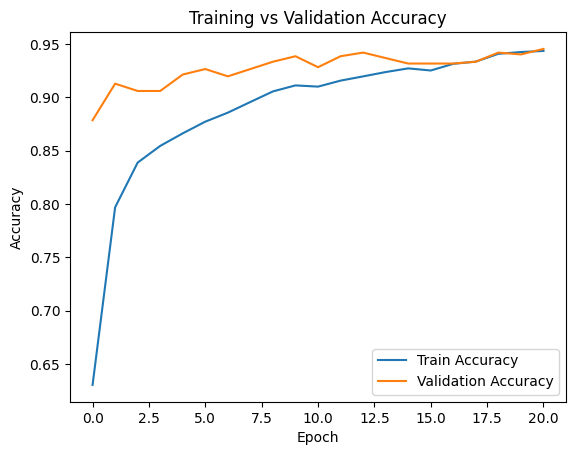

In [24]:
plt.figure()

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

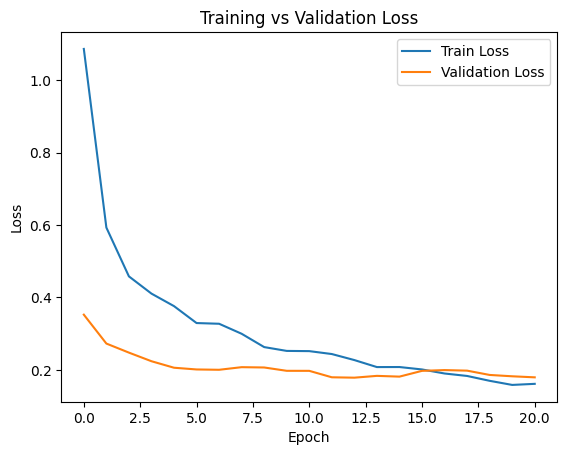

In [25]:
plt.figure()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [26]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 938ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 894ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 809ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 970ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 814ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 920ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 738ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 769ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 811ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 819ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 892ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 869ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 888ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 887ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 790ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 796ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 842ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 888ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 878ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 752

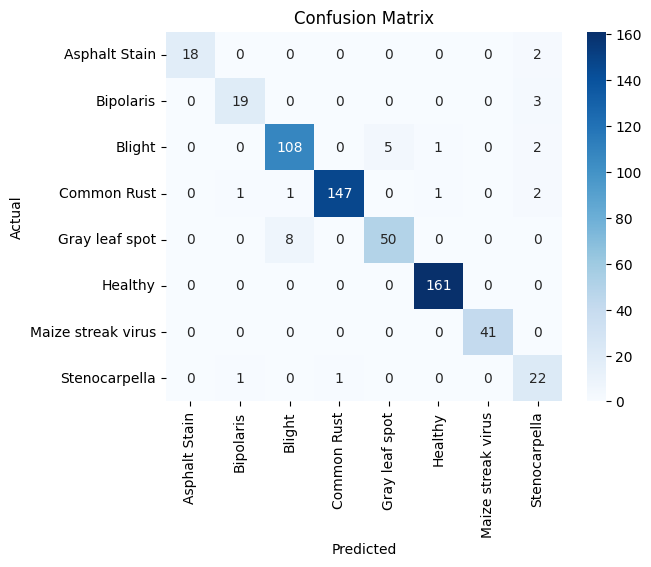

In [28]:
class_names = [
    "Asphalt Stain",
    "Bipolaris",
    "Blight",
    "Common Rust",
    "Gray leaf spot",
    "Healthy",
    "Maize streak virus",
    "Stenocarpella"
]

cm = confusion_matrix(y_true, y_pred)

plt.figure()

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [29]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

                    precision    recall  f1-score   support

     Asphalt Stain       1.00      0.90      0.95        20
         Bipolaris       0.90      0.86      0.88        22
            Blight       0.92      0.93      0.93       116
       Common Rust       0.99      0.97      0.98       152
    Gray leaf spot       0.91      0.86      0.88        58
           Healthy       0.99      1.00      0.99       161
Maize streak virus       1.00      1.00      1.00        41
     Stenocarpella       0.71      0.92      0.80        24

          accuracy                           0.95       594
         macro avg       0.93      0.93      0.93       594
      weighted avg       0.96      0.95      0.95       594



In [30]:
y_scores = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_scores.extend(preds)

y_scores = np.array(y_scores)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 818ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 863ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 838ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 794ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 886ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 855ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 846ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 904ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 809ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 831ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 926ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 887ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 793ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 798ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 784ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 868ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 862ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 861ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 868ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 863ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 837ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 862ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 872ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

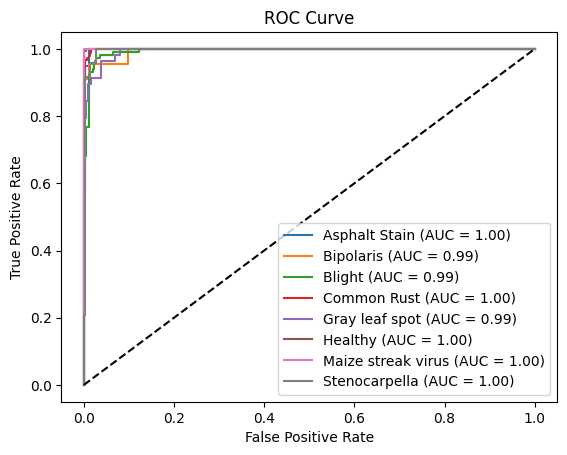

In [31]:
from sklearn.preprocessing import label_binarize

n_classes = len(class_names)

y_true_bin = label_binarize(y_true, classes=range(n_classes))

plt.figure()

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend()

plt.show()

In [32]:
model.save("maize_disease_efficientnetb3_cbam.keras")

print("Model saved successfully.")

Model saved successfully.


In [33]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("maize_disease_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model saved successfully.")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmprgzeujtl\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmprgzeujtl\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmprgzeujtl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  2434236861136: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2434236859216: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2434228446288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228446672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228445520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228447824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228448400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228447248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228445904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2434228448208: TensorSpec(shape=(), dtype=tf.resource

In [34]:
history
history_fine

In [35]:
import pandas as pd

# Combine both histories
history_dict = history.history
history_fine_dict = history_fine.history

for key in history_dict:
    history_dict[key] = history_dict[key] + history_fine_dict[key]

history_df = pd.DataFrame(history_dict)

history_df.to_csv("training_history.csv", index=False)

print("Training history saved.")

Training history saved.


In [36]:
import pandas as pd

history_df = pd.read_csv("training_history.csv")
# run this if you want to create graphs again


In [4]:
import tensorflow as tf
import numpy as np
import time


model_path = r"D:\Maize\Dataset\maize_disease_model.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()


print(f"Input shape  : {input_details[0]['shape']}")
print(f"Input dtype  : {input_details[0]['dtype']}")
print(f"Output shape : {output_details[0]['shape']}")

input_shape = input_details[0]['shape']
input_dtype = input_details[0]['dtype']

dummy_input = np.random.randint(
    0, 256,
    size=input_shape,
    dtype=np.uint8
).astype(input_dtype)

print(f"\nDummy input shape: {dummy_input.shape}")


print("")
for _ in range(3):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
print("")


times = []

for i in range(50):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])
    end = time.perf_counter()
    times.append((end - start) * 1000)



print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")


Input shape  : [  1 256 256   3]
Input dtype  : <class 'numpy.float32'>
Output shape : [1 8]

Dummy input shape: (1, 256, 256, 3)


Average latency : 99.53 ms
Std deviation   : 4.77 ms
Min latency     : 93.44 ms
Max latency     : 115.87 ms
Median latency  : 97.63 ms
